# 보드 눈금 보정 — 보드 dBFS ↔ 실제 dB SPL (Step8d)

> 2026-10-27 녹음 · 녹음 도구 [`board/stream_capture.py`](../board/stream_capture.py) · 커널: `Tools/.venv`
> 결론은 마지막 절에 **결론 후보**로만 적는다. 사용자가 확인한 뒤 Step8d 결과·결정으로 올린다.

**질문:** 보드가 0 dBFS(풀스케일 사인)를 낼 때 마이크 앞 소리는 몇 dB SPL인가? 이 숫자 **K**가 있으면 보드가 잰 모든 크기를 실제 dB SPL로 읽을 수 있다: `dB SPL = dBFS + K`. 탐지거리 식 r = 10^((L₁ − N − T) ÷ 20)의 L₁(음원 크기)과 N(잡음)을 같은 눈금으로 읽는 기준이다.

| 조건 | 값 |
|---|---|
| 재생 파일 | `DataSet/_playback/50_cal_tones.wav` — [1 kHz 15 s · 쉼 5 s · 250 Hz 15 s · 쉼 5 s] × 3, −6 dBFS |
| 음원 | 노트북 스피커, 배열 0° 방향 0.5 m, 같은 높이 |
| 소음계 | 휴대폰 Samsung SM-S926N, 앱 "소음 측정기 (KTW Apps)", 가중치 **Z**, 마이크를 배열 중심 옆 5 cm 안 |
| 소음계 값 (사용자 기록) | 1 kHz: 78.4 · 77.6 · 77.5 dBZ / 250 Hz: 60.6 · 60.6 · 60.6 dBZ |
| 보드 녹음 | `Tools/dumps/stream/cal_spl/` (12.5 kHz · 3채널 · int16), 트리머는 Step8d 동안 고정 |
| dBFS 정의 | 사인 기준: 10·log₁₀(2 × 평균제곱), 신호는 int16 ÷ 32768. 풀스케일 사인 = 0 dBFS (`stream_capture.py`의 `levels()`와 같음) |

**한계:** 휴대폰 소음계는 보정기가 아니라 절대값이 ±2 dB 안팎 틀릴 수 있다 (추정). 휴대폰 마이크와 보드 마이크의 위치가 5 cm 안에서 다르다. 250 Hz는 노트북 스피커가 약하게 낸다.

In [1]:
import json, csv, wave
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic") if f in _have), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
REC = "../dumps/stream/cal_spl"
SPL = {"1k": [78.4, 77.6, 77.5], "250": [60.6, 60.6, 60.6]}   # 사용자가 적은 소음계 값 (dBZ)
w = wave.open(f"{REC}/seg_000.wav"); FS = w.getframerate()
x = np.frombuffer(w.readframes(w.getnframes()), dtype="<i2").reshape(-1, 3).astype(float) / 32768
x = x - x.mean(0)                                      # 채널마다 직류 제거
dbfs = lambda ms: 10 * np.log10(2 * ms + 1e-20)        # 사인 기준 dBFS
print(f"샘플레이트 {FS} Hz, 길이 {len(x) / FS:.1f} s, 채널 {x.shape[1]}")

샘플레이트 12500 Hz, 길이 176.6 s, 채널 3


## 1. 녹음 무결성

유실·오버런·CRC·클리핑을 본다. 클리핑이 톤 구간에 있으면 그 톤은 쓸 수 없다.

In [2]:
S = json.load(open(f"{REC}/summary.json", encoding="utf-8"))
print("판정:", S["criteria"])
pk = list(csv.DictReader(open(f"{REC}/packets.csv")))
clip_t = [float(r["t_rx"]) for r in pk if int(r["flags"]) & 1]
print(f"클리핑 패킷 {len(clip_t)}개 / {len(pk)}개, 시각(수신 기준) {clip_t}")

판정: {'loss': True, 'ovr': True, 'crc': True, 'clip': False, 'time_restore': True}
클리핑 패킷 1개 / 8623개, 시각(수신 기준) [11.8427]


## 2. 시간축 개요 — 톤 구간 찾기

0.5 s마다 4096점 FFT로 세 대역의 크기를 잰다: 1 kHz(±2 %), 250 Hz(±4 %), 그리고 방향·탐지가 쓰는 300 ~ 3000 Hz.
**예상:** 쉬는 구간은 바닥 잡음(약 −58 dBFS 근처), 톤 구간은 그보다 수십 dB 위. 250 Hz 톤은 소음계로 1 kHz보다 17 dB 작았으니 보드에서도 그 정도 작아야 한다.

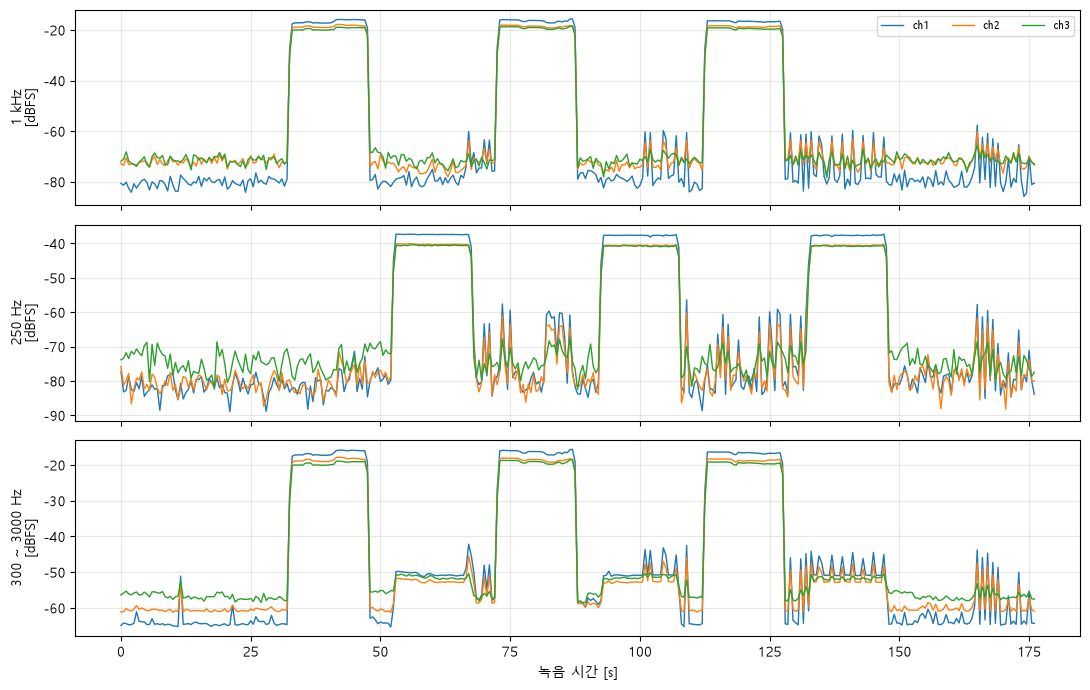

In [3]:
NF = 4096; WIN = np.hanning(NF); F = np.fft.rfftfreq(NF, 1 / FS)
def band_ms(seg, lo, hi, win=None):
    win = np.hanning(len(seg)) if win is None else win
    X = np.fft.rfft(seg * win); f = np.fft.rfftfreq(len(seg), 1 / FS)
    m = (f >= lo) & (f < hi)
    return 2 * np.sum(np.abs(X[m]) ** 2) / (len(seg) * np.sum(win ** 2))   # 대역 안 평균제곱 (Parseval)
T = np.arange(0, len(x) / FS - NF / FS, 0.5)
B = {k: np.array([[dbfs(band_ms(x[int(t * FS):int(t * FS) + NF, c], lo, hi, WIN)) for c in range(3)] for t in T])
     for k, (lo, hi) in {"1 kHz": (980, 1020), "250 Hz": (240, 260), "300 ~ 3000 Hz": (300, 3000)}.items()}
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for a, (k, v) in zip(ax, B.items()):
    for c in range(3): a.plot(T, v[:, c], lw=1, label=f"ch{c + 1}")
    a.set_ylabel(f"{k}\n[dBFS]"); a.grid(alpha=.3)
ax[0].legend(ncol=3, fontsize=8); ax[-1].set_xlabel("녹음 시간 [s]"); plt.tight_layout(); plt.show()

In [4]:
# 톤 구간 자동 찾기: ch1에서 그 대역이 바닥보다 20 dB 이상 높은 연속 구간
segs = []
for k, key in (("1k", "1 kHz"), ("250", "250 Hz")):
    on = B[key][:, 0] > np.median(B[key][:, 0]) + 20
    i = 0
    while i < len(on):
        if on[i]:
            j = i
            while j + 1 < len(on) and on[j + 1]: j += 1
            if T[j] - T[i] > 5: segs.append((k, T[i], T[j] + NF / FS))
            i = j + 1
        else: i += 1
segs.sort(key=lambda s: s[1])
for s in segs: print(f"{s[0]:>4s}: {s[1]:6.1f} ~ {s[2]:6.1f} s ({s[2] - s[1]:.1f} s)")
assert [s[0] for s in segs] == ["1k", "250"] * 3, "톤 순서가 파일과 다르다" 

  1k:   32.5 ~   47.8 s (15.3 s)
 250:   52.5 ~   67.8 s (15.3 s)
  1k:   72.5 ~   87.8 s (15.3 s)
 250:   92.5 ~  107.8 s (15.3 s)
  1k:  112.5 ~  127.8 s (15.3 s)
 250:  132.5 ~  147.8 s (15.3 s)


## 3. 한 톤 손으로 따라가기 — 첫 1 kHz, ch1

톤의 앞뒤 2 s는 버리고 가운데 약 11 s를 쓴다 (켜고 끌 때의 흔들림을 빼려고).
1. 파형 5 ms를 그려 사인인지 본다 (1 kHz면 5 ms에 5주기).
2. 평균제곱 → 사인 기준 dBFS → K = 소음계 값 − dBFS.

**예상(손계산):** 진폭 A인 사인의 평균제곱은 A²/2라서 dBFS = 10·log₁₀(2 × A²/2) = 20·log₁₀ A. 예를 들어 A = 0.1(풀스케일의 10 %)이면 −20 dBFS.

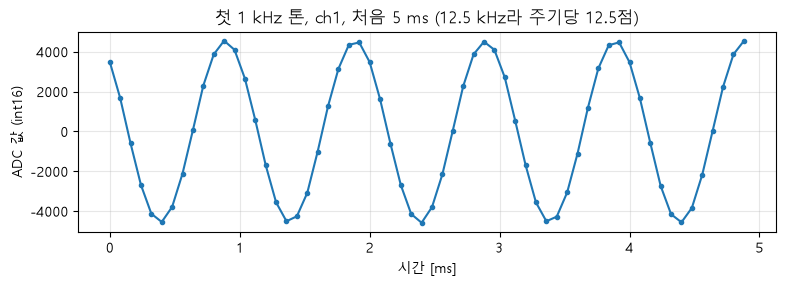

구간 34.5 ~ 45.8 s, 141596 샘플
전체 평균제곱 1.097e-02 → -16.59 dBFS (대역 밖 잡음 포함)
1 kHz 대역 평균제곱 1.041e-02 → 진폭 A = √(2 × 평균제곱) = 0.1443 (= int16 4729)
dBFS = 20·log₁₀ 0.1443 = -16.81 dBFS
K = 소음계 78.4 − (-16.81) = 95.21 dB SPL @ 0 dBFS


In [5]:
k0, a0, b0 = segs[0]
s = x[int((a0 + 2) * FS):int((b0 - 2) * FS), 0]
t5 = np.arange(int(0.005 * FS)) / FS * 1000
plt.figure(figsize=(9, 2.6)); plt.plot(t5, s[:len(t5)] * 32768, ".-"); plt.xlabel("시간 [ms]"); plt.ylabel("ADC 값 (int16)")
plt.title("첫 1 kHz 톤, ch1, 처음 5 ms (12.5 kHz라 주기당 12.5점)"); plt.grid(alpha=.3); plt.show()
ms_all = np.mean(s ** 2); ms_band = band_ms(s, 980, 1020)
A = np.sqrt(2 * ms_band)
print(f"구간 {a0 + 2:.1f} ~ {b0 - 2:.1f} s, {len(s)} 샘플")
print(f"전체 평균제곱 {ms_all:.3e} → {dbfs(ms_all):.2f} dBFS (대역 밖 잡음 포함)")
print(f"1 kHz 대역 평균제곱 {ms_band:.3e} → 진폭 A = √(2 × 평균제곱) = {A:.4f} (= int16 {A * 32768:.0f})")
print(f"dBFS = 20·log₁₀ {A:.4f} = {20 * np.log10(A):.2f} dBFS")
print(f"K = 소음계 {SPL['1k'][0]} − ({20 * np.log10(A):.2f}) = {SPL['1k'][0] - 20 * np.log10(A):.2f} dB SPL @ 0 dBFS")

## 4. 여섯 톤 × 세 채널의 K

▶ **예측 지점 (T1)** — 아래 표를 보기 전에 대화에서 예측한다.

각 톤의 가운데 11 s에서 톤 대역(±3 %) 크기를 dBFS로 재고, 같은 톤의 소음계 값에서 빼서 K를 낸다.

In [6]:
rows = []; K = {"1k": [], "250": []}
rep = {"1k": 0, "250": 0}
for k, a, b in segs:
    f0 = 1000 if k == "1k" else 250
    seg = x[int((a + 2) * FS):int((b - 2) * FS)]
    L = [dbfs(band_ms(seg[:, c], f0 * 0.97, f0 * 1.03)) for c in range(3)]
    spl = SPL[k][rep[k]]; rep[k] += 1
    K[k].append([spl - v for v in L])
    rows.append((k, a, spl, L))
print(f"{'톤':>4s} {'시작':>6s} {'소음계':>6s} | {'ch1 dBFS':>9s} {'ch2':>7s} {'ch3':>7s} | {'K ch1':>6s} {'K ch2':>6s} {'K ch3':>6s}")
for k, a, spl, L in rows:
    print(f"{k:>4s} {a:6.1f} {spl:6.1f} | {L[0]:9.2f} {L[1]:7.2f} {L[2]:7.2f} | {spl - L[0]:6.2f} {spl - L[1]:6.2f} {spl - L[2]:6.2f}")
Karr = {k: np.array(v) for k, v in K.items()}
for k in ("1k", "250"):
    print(f"\n{k}: K 평균 ch1 {Karr[k][:, 0].mean():.2f} · ch2 {Karr[k][:, 1].mean():.2f} · ch3 {Karr[k][:, 2].mean():.2f} dB SPL @ 0 dBFS")
    print(f"     세 번 사이 차이 (최대 − 최소): ch1 {np.ptp(Karr[k][:, 0]):.2f} · ch2 {np.ptp(Karr[k][:, 1]):.2f} · ch3 {np.ptp(Karr[k][:, 2]):.2f} dB  (기준 ≤ 1 dB)")

   톤     시작    소음계 |  ch1 dBFS     ch2     ch3 |  K ch1  K ch2  K ch3
  1k   32.5   78.4 |    -16.81  -18.63  -19.70 |  95.21  97.03  98.10
 250   52.5   60.6 |    -37.42  -40.31  -40.55 |  98.02 100.91 101.15
  1k   72.5   77.6 |    -16.43  -18.61  -19.21 |  94.03  96.21  96.81
 250   92.5   60.6 |    -37.60  -40.50  -40.75 |  98.20 101.10 101.35
  1k  112.5   77.5 |    -16.63  -18.82  -19.50 |  94.13  96.32  97.00
 250  132.5   60.6 |    -37.64  -40.55  -40.79 |  98.24 101.15 101.39

1k: K 평균 ch1 94.46 · ch2 96.52 · ch3 97.30 dB SPL @ 0 dBFS
     세 번 사이 차이 (최대 − 최소): ch1 1.18 · ch2 0.82 · ch3 1.28 dB  (기준 ≤ 1 dB)

250: K 평균 ch1 98.15 · ch2 101.06 · ch3 101.30 dB SPL @ 0 dBFS
     세 번 사이 차이 (최대 − 최소): ch1 0.23 · ch2 0.24 · ch3 0.24 dB  (기준 ≤ 1 dB)


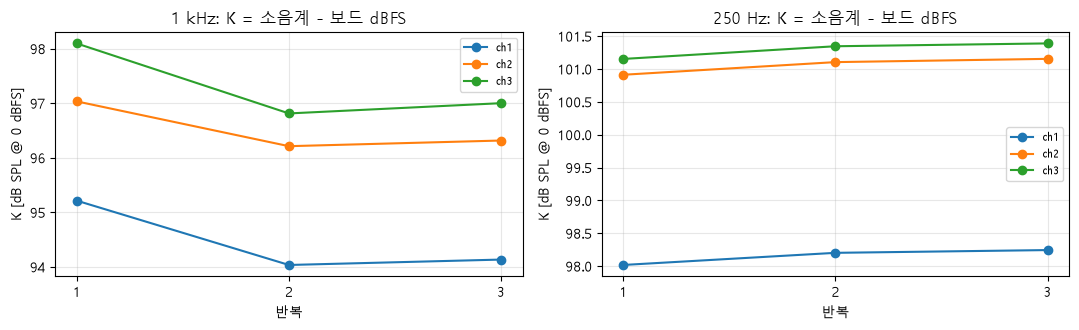

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for i, k in enumerate(("1k", "250")):
    for c in range(3): ax[i].plot([1, 2, 3], Karr[k][:, c], "o-", label=f"ch{c + 1}")
    ax[i].set_title(f"{'1 kHz' if k == '1k' else '250 Hz'}: K = 소음계 - 보드 dBFS"); ax[i].set_xticks([1, 2, 3]); ax[i].set_xlabel("반복")
    ax[i].set_ylabel("K [dB SPL @ 0 dBFS]"); ax[i].grid(alpha=.3); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. 주파수에 따른 차이 — K(250 Hz) − K(1 kHz)

소음계(Z 가중)가 평평하다고 보면, 이 차이는 **보드 마이크 체인(캡슐 + MAX4466 + 결합 커패시터 + FIR)이 250 Hz를 1 kHz보다 얼마나 덜/더 키우는가**다.
0이면 300 ~ 3000 Hz 밖까지 같은 K 하나로 읽어도 된다. 크면 주파수마다 K를 따로 써야 한다.

In [8]:
for c in range(3):
    d = Karr["250"][:, c].mean() - Karr["1k"][:, c].mean()
    print(f"ch{c + 1}: K(250) − K(1k) = {d:+.2f} dB  → 보드가 250 Hz를 1 kHz보다 {abs(d):.1f} dB {'덜' if d > 0 else '더'} 키운다")

ch1: K(250) − K(1k) = +3.69 dB  → 보드가 250 Hz를 1 kHz보다 3.7 dB 덜 키운다
ch2: K(250) − K(1k) = +4.54 dB  → 보드가 250 Hz를 1 kHz보다 4.5 dB 덜 키운다
ch3: K(250) − K(1k) = +3.99 dB  → 보드가 250 Hz를 1 kHz보다 4.0 dB 덜 키운다


### 5b. 휴대폰 녹음으로 나눠 보기 — 1 kHz와 250 Hz의 차이는 어느 쪽에서 생기나

같은 스피커 소리를 세 가지로 잰 **"1 kHz − 250 Hz" 차이**를 비교한다.

| | 무엇 | 파일 |
|---|---|---|
| ① 소음계 | 앱이 보여 준 값의 차이 (사용자 기록) | 위 `SPL` |
| ② 휴대폰 원시 | 같은 휴대폰이 녹음한 파일의 대역 크기 차이 (앱 보정 없음) | `cal_spl/phone_2026-10-27_23-20-06.mp3` (사용자: 10:40 이후 1 kHz·250 Hz 3세트, 그 뒤 소리는 무시. 15 s 톤만 고르려고 12 s보다 짧은 소리는 뺀다) |
| ③ 보드 | 4절 보드 dBFS의 차이 | `cal_spl/seg_000.wav` |

스피커가 250 Hz를 약하게 내는 정도는 셋 모두에 똑같이 들어가므로 **차이를 빼면 사라진다.** 남는 것은 각 마이크(와 앱)의 응답 차이다.
- ① ≈ ②이면 앱은 휴대폰 마이크 신호를 거의 그대로 dB로 바꾼 것이다 → 소음계 값 = 휴대폰 마이크의 응답.
- ③ − ②는 **보드 마이크 체인과 휴대폰 마이크의 상대 응답**이다. 둘 중 어느 쪽이 평평한지는 이 비교로 가릴 수 없다 (기준 마이크가 없음).

**한계:** 확장자는 `.mp3`지만 내용은 WAV(16비트 PCM, 44.1 kHz, 모노)라 압축 손실은 없다. 휴대폰 녹음 앱이 자동 음량 조절(AGC)을 했을 수 있다 — 아래 그림에서 톤 하나 안의 크기가 평평한지, 세 번 반복이 같은지로 일부만 확인한다.

In [9]:
import soundfile as sf
ph, FSP = sf.read(f"{REC}/phone_2026-10-27_23-20-06.mp3", dtype="float64")
ph = ph if ph.ndim == 1 else ph[:, 0]
def band_ms_fs(seg, fs, lo, hi):
    win = np.hanning(len(seg)); X = np.fft.rfft(seg * win); f = np.fft.rfftfreq(len(seg), 1 / fs); m = (f >= lo) & (f < hi)
    return 2 * np.sum(np.abs(X[m]) ** 2) / (len(seg) * np.sum(win ** 2))
NP = 8192
TP = np.arange(600, min(len(ph) / FSP, 1000) - NP / FSP, 0.5)
BP = {k: np.array([dbfs(band_ms_fs(ph[int(t * FSP):int(t * FSP) + NP], FSP, lo, hi)) for t in TP]) for k, (lo, hi) in {"1k": (980, 1020), "250": (240, 260)}.items()}
psegs, short = [], []
for k in ("1k", "250"):
    on = BP[k] > np.median(BP[k]) + 20; i = 0
    while i < len(on):
        if on[i]:
            j = i
            while j + 1 < len(on) and on[j + 1]: j += 1
            (psegs if TP[j] - TP[i] > 12 else short).append((k, TP[i], TP[j] + NP / FSP))   # 톤은 15 s
            i = j + 1
        else: i += 1
psegs.sort(key=lambda s: s[1])
print("12 s보다 짧아서 뺀 구간:", [(k, round(float(a), 1), round(float(b - a), 1)) for k, a, b in sorted(short, key=lambda s: s[1])])
i0 = next(i for i, s in enumerate(psegs) if s[0] == "1k")
psegs = psegs[i0:i0 + 6]                                # 첫 1 kHz부터 여섯 개 (그 뒤 소리는 무시)
print(f"휴대폰 파일 {len(ph) / FSP:.0f} s, {FSP} Hz")
for s in psegs: print(f"{s[0]:>4s}: {s[1]:6.1f} ~ {s[2]:6.1f} s ({s[2] - s[1]:.1f} s)")
assert [s[0] for s in psegs] == ["1k", "250"] * 3, "휴대폰 녹음의 톤 순서가 파일과 다르다"

12 s보다 짧아서 뺀 구간: [('1k', 619.5, 0.2), ('1k', 644.0, 6.2), ('1k', 720.0, 1.2), ('250', 720.0, 0.2), ('1k', 725.0, 0.2), ('250', 725.0, 0.2), ('250', 731.0, 0.7), ('1k', 731.5, 0.2), ('250', 752.0, 0.2), ('250', 966.5, 0.2)]
휴대폰 파일 980 s, 44100 Hz
  1k:  783.5 ~  798.7 s (15.2 s)
 250:  803.5 ~  818.2 s (14.7 s)
  1k:  823.5 ~  838.2 s (14.7 s)
 250:  843.5 ~  858.2 s (14.7 s)
  1k:  863.5 ~  878.2 s (14.7 s)
 250:  883.5 ~  898.2 s (14.7 s)


In [10]:
PL = {"1k": [], "250": []}
for k, a, b in psegs:
    f0 = 1000 if k == "1k" else 250
    PL[k].append(dbfs(band_ms_fs(ph[int((a + 2) * FSP):int((b - 2) * FSP)], FSP, f0 * 0.97, f0 * 1.03)))
BL = {k: [r[3] for r in rows if r[0] == k] for k in ("1k", "250")}       # 4절 보드 dBFS [반복][채널]
print(f"{'반복':>4s} | {'① 소음계':>9s} | {'② 휴대폰 원시':>14s} | {'③ 보드 ch1':>10s} {'ch2':>6s} {'ch3':>6s}")
D1, D2, D3 = [], [], []
for r in range(3):
    d1 = SPL["1k"][r] - SPL["250"][r]; d2 = PL["1k"][r] - PL["250"][r]; d3 = [BL["1k"][r][c] - BL["250"][r][c] for c in range(3)]
    D1.append(d1); D2.append(d2); D3.append(d3)
    print(f"{r + 1:4d} | {SPL['1k'][r]:.1f} - {SPL['250'][r]:.1f} = {d1:5.2f} | {PL['1k'][r]:6.2f} - ({PL['250'][r]:6.2f}) = {d2:5.2f} | {d3[0]:10.2f} {d3[1]:6.2f} {d3[2]:6.2f}")
D3 = np.array(D3)
print(f"\n평균: ① {np.mean(D1):.2f} · ② {np.mean(D2):.2f} · ③ ch1 {D3[:, 0].mean():.2f} · ch2 {D3[:, 1].mean():.2f} · ch3 {D3[:, 2].mean():.2f} dB")
print(f"① - ② = {np.mean(D1) - np.mean(D2):+.2f} dB  (앱 보정의 크기)")
print("③ - ② (보드 체인이 휴대폰 마이크보다 250 Hz를 1 kHz 대비 덜 받는 정도):", ", ".join(f"ch{c + 1} {D3[:, c].mean() - np.mean(D2):+.2f}" for c in range(3)), "dB")
print("참고 5절 K(250) - K(1k):", ", ".join(f"ch{c + 1} {Karr['250'][:, c].mean() - Karr['1k'][:, c].mean():+.2f}" for c in range(3)), "dB  (= ③ - ①)")

  반복 |     ① 소음계 |       ② 휴대폰 원시 |   ③ 보드 ch1    ch2    ch3
   1 | 78.4 - 60.6 = 17.80 | -28.34 - (-45.79) = 17.45 |      20.60  21.68  20.86
   2 | 77.6 - 60.6 = 17.00 | -29.82 - (-45.72) = 15.91 |      21.17  21.89  21.53
   3 | 77.5 - 60.6 = 16.90 | -29.22 - (-45.84) = 16.62 |      21.01  21.74  21.29

평균: ① 17.23 · ② 16.66 · ③ ch1 20.93 · ch2 21.77 · ch3 21.23 dB
① - ② = +0.57 dB  (앱 보정의 크기)
③ - ② (보드 체인이 휴대폰 마이크보다 250 Hz를 1 kHz 대비 덜 받는 정도): ch1 +4.27, ch2 +5.11, ch3 +4.57 dB
참고 5절 K(250) - K(1k): ch1 +3.69, ch2 +4.54, ch3 +3.99 dB  (= ③ - ①)


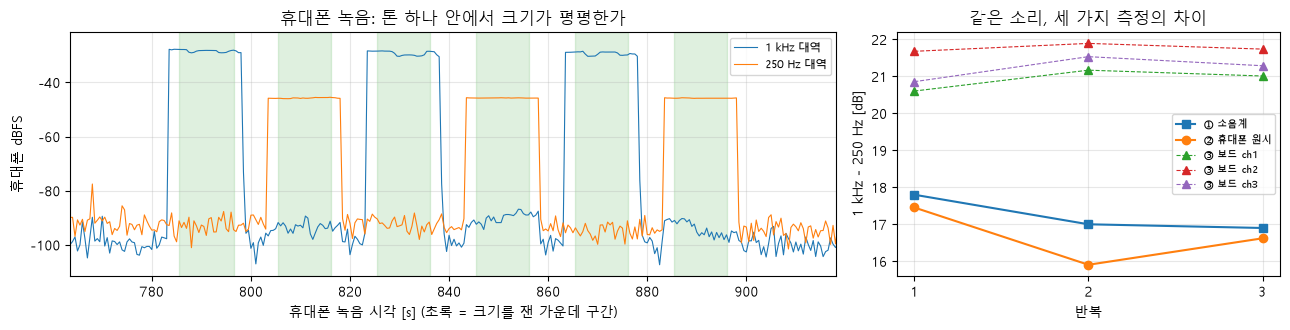

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[2, 1]))
for k, cl in (("1k", "C0"), ("250", "C1")): ax[0].plot(TP, BP[k], lw=.8, color=cl, label=("1 kHz" if k == "1k" else "250 Hz") + " 대역")
for k, a, b in psegs: ax[0].axvspan(a + 2, b - 2, color="C2", alpha=.15)
ax[0].set_xlim(psegs[0][1] - 20, psegs[-1][2] + 20); ax[0].set_xlabel("휴대폰 녹음 시각 [s] (초록 = 크기를 잰 가운데 구간)"); ax[0].set_ylabel("휴대폰 dBFS"); ax[0].grid(alpha=.3); ax[0].legend(fontsize=8)
ax[0].set_title("휴대폰 녹음: 톤 하나 안에서 크기가 평평한가")
x3 = np.arange(1, 4)
ax[1].plot(x3, D1, "s-", label="① 소음계"); ax[1].plot(x3, D2, "o-", label="② 휴대폰 원시")
for c in range(3): ax[1].plot(x3, D3[:, c], "^--", lw=.8, label=f"③ 보드 ch{c + 1}")
ax[1].set_xticks(x3); ax[1].set_xlabel("반복"); ax[1].set_ylabel("1 kHz - 250 Hz [dB]"); ax[1].grid(alpha=.3); ax[1].legend(fontsize=7)
ax[1].set_title("같은 소리, 세 가지 측정의 차이")
plt.tight_layout(); plt.show()

**그림에서 볼 것:** 왼쪽 — 톤 구간 안의 크기 곡선이 평평한지 (기울거나 계단이 있으면 AGC 의심). 오른쪽 — ①과 ②가 겹치는지, ③이 둘에서 얼마나 떨어져 있는지, 세 번 반복이 같은 간격인지.

## 6. 조용한 바닥을 dB SPL로

첫 톤 전의 긴 조용한 구간(손뼉 뒤 ~ 첫 톤 1 s 전)에서 300 ~ 3000 Hz 크기를 재고 K(1 kHz)를 더해 **"바닥이 소리라면 몇 dB SPL인가"**로 바꾼다.
이 값이 탐지거리 식의 N 아래 한계다 (조용한 곳에서 N ≈ max(주변 소음, 이 바닥)).

**예상:** 예산 페이지의 추정은 캡슐 잡음 34 dB SPL, 앰프 뒤 잡음 약 27 dB SPL이었다.

In [12]:
clip_end = 13.0                                         # 손뼉(11.8 s) 뒤
quiet = [(clip_end, segs[0][1] - 1)] + [(segs[i][2] + 1, segs[i + 1][1] - 1) for i in range(len(segs) - 1)]
quiet = [(a, b) for a, b in quiet if b - a >= 2]
Kq = Karr["1k"].mean(0)
Lq = np.array([[dbfs(band_ms(x[int(a * FS):int(b * FS), c], 300, 3000)) for c in range(3)] for a, b in quiet])
a, b = quiet[0]
print(f"바닥 = 첫 조용한 구간 {a:.1f} ~ {b:.1f} s ({b - a:.1f} s)")
for c in range(3):
    print(f"ch{c + 1}: 300 ~ 3000 Hz {Lq[0, c]:6.1f} dBFS + K {Kq[c]:.1f} = {Lq[0, c] + Kq[c]:5.1f} dB SPL 상당")
print()
print("참고 — 톤 사이 쉼(각 2.7 s, 톤 끝 1 s 뒤부터):")
for (a, b), L in zip(quiet[1:], Lq[1:]):
    print(f"  {a:6.1f} ~ {b:6.1f} s: ch1 {L[0]:6.1f} · ch2 {L[1]:6.1f} · ch3 {L[2]:6.1f} dBFS  (첫 구간보다 ch1 {L[0] - Lq[0, 0]:+.1f} dB)")

바닥 = 첫 조용한 구간 13.0 ~ 31.5 s (18.5 s)
ch1: 300 ~ 3000 Hz  -62.4 dBFS + K 94.5 =  32.0 dB SPL 상당
ch2: 300 ~ 3000 Hz  -60.1 dBFS + K 96.5 =  36.4 dB SPL 상당
ch3: 300 ~ 3000 Hz  -56.8 dBFS + K 97.3 =  40.5 dB SPL 상당

참고 — 톤 사이 쉼(각 2.7 s, 톤 끝 1 s 뒤부터):
    48.8 ~   51.5 s: ch1  -63.5 · ch2  -60.4 · ch3  -55.3 dBFS  (첫 구간보다 ch1 -1.1 dB)
    68.8 ~   71.5 s: ch1  -49.3 · ch2  -52.5 · ch3  -55.8 dBFS  (첫 구간보다 ch1 +13.1 dB)
    88.8 ~   91.5 s: ch1  -53.3 · ch2  -55.7 · ch3  -55.9 dBFS  (첫 구간보다 ch1 +9.1 dB)
   108.8 ~  111.5 s: ch1  -54.3 · ch2  -56.4 · ch3  -56.5 dBFS  (첫 구간보다 ch1 +8.2 dB)
   128.8 ~  131.5 s: ch1  -54.5 · ch2  -56.6 · ch3  -57.4 dBFS  (첫 구간보다 ch1 +7.9 dB)


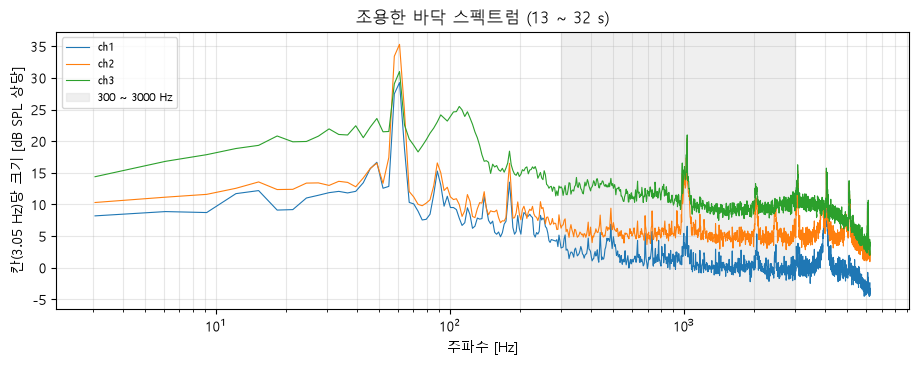

In [13]:
a, b = quiet[0]
nper = 4096
fig = plt.figure(figsize=(11, 3.6))
for c in range(3):
    seg = x[int(a * FS):int(b * FS), c]; n = len(seg) // nper
    P = np.mean([np.abs(np.fft.rfft(seg[i * nper:(i + 1) * nper] * np.hanning(nper))) ** 2 for i in range(n)], 0)
    P = P * 2 / (nper * np.sum(np.hanning(nper) ** 2))          # 칸 하나의 평균제곱
    f = np.fft.rfftfreq(nper, 1 / FS)
    plt.semilogx(f[1:], 10 * np.log10(2 * P[1:]) + Kq[c], lw=.8, label=f"ch{c + 1}")
plt.axvspan(300, 3000, color="0.85", alpha=.4, label="300 ~ 3000 Hz")
plt.xlabel("주파수 [Hz]"); plt.ylabel("칸(3.05 Hz)당 크기 [dB SPL 상당]"); plt.title(f"조용한 바닥 스펙트럼 ({a:.0f} ~ {b:.0f} s)")
plt.grid(alpha=.3, which="both"); plt.legend(fontsize=8); plt.show()

## 7. 발견

- **반복 차이가 기준을 넘은 것은 소음계 쪽이다.** 보드의 1 kHz 세 번은 ch1 −16.81 · −16.43 · −16.63 dBFS로 0.4 dB 안인데, 소음계 값이 78.4 · 77.6 · 77.5로 0.9 dB 흔들렸다 (첫 값만 높음). 아래 셀에서 보드 쪽 흔들림만 따로 뽑는다.
- **톤 사이 쉼은 바닥으로 쓸 수 없다.** 6절 참고 출력처럼 톤 끝 1 s 뒤에도 첫 조용한 구간보다 수 dB ~ 13 dB 높다 (잔향, 사람 움직임 추정). 바닥은 녹음 앞쪽 긴 조용한 구간으로 잰다.
- **전원을 뺀 녹음과 바닥이 가깝다.** 마이크 전원 없이 녹음했던 첫 `cal_spl`(덮어써서 지금은 없음)은 채널 RMS −58.6 · −55.1 · −55.3 dBFS, ch1의 300 ~ 3000 Hz는 약 −65 dBFS였다 (대화 중 빠른 확인 값, 이 노트북에서 재현 불가). 전원이 있는 지금 ch1 300 ~ 3000 Hz 바닥은 아래 셀 값이다. 차이가 몇 dB뿐이면 조용한 방의 바닥은 **보드·ADC 전기 잡음과 캡슐·방 소리가 비슷한 크기**로 섞인 것이다.

In [14]:
a, b = quiet[0]
q = x[int(a * FS):int(b * FS)]
print(f"보드 1 kHz dBFS 세 번 (ch1·ch2·ch3): {[np.round([r[3][c] for r in rows if r[0] == '1k'], 2).tolist() for c in range(3)]}")
print(f"  → 보드 쪽 흔들림(최대 − 최소): {[round(float(np.ptp([r[3][c] for r in rows if r[0] == '1k'])), 2) for c in range(3)]} dB, 소음계 쪽 {np.ptp(SPL['1k']):.2f} dB")
print(f"지금(전원 있음) 조용한 구간 채널 RMS: {np.round([dbfs(np.mean(q[:, c] ** 2)) for c in range(3)], 1)} dBFS, ch1 300 ~ 3000 Hz {Lq[0, 0]:.1f} dBFS")
print("전원 없을 때(덮어쓴 첫 녹음, 대화 기록): RMS [-58.6 -55.1 -55.3] dBFS, ch1 300 ~ 3000 Hz 약 -65 dBFS")

보드 1 kHz dBFS 세 번 (ch1·ch2·ch3): [[-16.81, -16.43, -16.63], [-18.63, -18.61, -18.82], [-19.7, -19.21, -19.5]]
  → 보드 쪽 흔들림(최대 − 최소): [0.38, 0.2, 0.48] dB, 소음계 쪽 0.90 dB
지금(전원 있음) 조용한 구간 채널 RMS: [-57.4 -54.6 -52.6] dBFS, ch1 300 ~ 3000 Hz -62.4 dBFS
전원 없을 때(덮어쓴 첫 녹음, 대화 기록): RMS [-58.6 -55.1 -55.3] dBFS, ch1 300 ~ 3000 Hz 약 -65 dBFS


## 8. 결론 후보 (사용자 확인 전)

아래 셀이 위 결과에서 숫자를 다시 뽑는다.

In [15]:
print("1. 보드 눈금 K (1 kHz, 세 번 평균):", ", ".join(f"ch{c + 1} {Karr['1k'][:, c].mean():.1f}" for c in range(3)), "dB SPL @ 0 dBFS  (근거 4절)")
ok = all(np.ptp(Karr['1k'][:, c]) <= 1 for c in range(3))
print(f"2. 반복 차이 ≤ 1 dB 기준 (1 kHz): {'만족' if ok else '미달'} — 최대 {max(np.ptp(Karr['1k'][:, c]) for c in range(3)):.2f} dB  (근거 4절)")
print("3. K(250) − K(1k):", ", ".join(f"ch{c + 1} {Karr['250'][:, c].mean() - Karr['1k'][:, c].mean():+.1f}" for c in range(3)), "dB  (근거 5절)")
print("4. 조용한 방 300 ~ 3000 Hz 바닥:", ", ".join(f"ch{c + 1} {Lq[0, c] + Kq[c]:.1f}" for c in range(3)), "dB SPL 상당  (근거 6절, 첫 조용한 구간)")
print("5. 반복 차이 초과는 소음계 쪽 흔들림 (보드 0.4 dB 안) — 기준을 '보드 dBFS 반복 차이 ≤ 1 dB'로 볼지는 사용자 판단  (근거 7절)")
print("6. 1 kHz - 250 Hz 차이: 소음계", f"{np.mean(D1):.1f}", "· 휴대폰 원시", f"{np.mean(D2):.1f}", "· 보드 ch1", f"{D3[:, 0].mean():.1f}", "dB → 차이는 보드 체인 vs 휴대폰 마이크 사이 (어느 쪽이 평평한지는 모름)  (근거 5b절)")
print("\n아직 모르는 것: 휴대폰 소음계의 절대 오차(±2 dB 추정), 바닥이 전기 잡음인지 캡슐 잡음인지(전원 유무 비교는 재현 불가 → 방음 녹음으로 확인)")

1. 보드 눈금 K (1 kHz, 세 번 평균): ch1 94.5, ch2 96.5, ch3 97.3 dB SPL @ 0 dBFS  (근거 4절)
2. 반복 차이 ≤ 1 dB 기준 (1 kHz): 미달 — 최대 1.28 dB  (근거 4절)
3. K(250) − K(1k): ch1 +3.7, ch2 +4.5, ch3 +4.0 dB  (근거 5절)
4. 조용한 방 300 ~ 3000 Hz 바닥: ch1 32.0, ch2 36.4, ch3 40.5 dB SPL 상당  (근거 6절, 첫 조용한 구간)
5. 반복 차이 초과는 소음계 쪽 흔들림 (보드 0.4 dB 안) — 기준을 '보드 dBFS 반복 차이 ≤ 1 dB'로 볼지는 사용자 판단  (근거 7절)
6. 1 kHz - 250 Hz 차이: 소음계 17.2 · 휴대폰 원시 16.7 · 보드 ch1 20.9 dB → 차이는 보드 체인 vs 휴대폰 마이크 사이 (어느 쪽이 평평한지는 모름)  (근거 5b절)

아직 모르는 것: 휴대폰 소음계의 절대 오차(±2 dB 추정), 바닥이 전기 잡음인지 캡슐 잡음인지(전원 유무 비교는 재현 불가 → 방음 녹음으로 확인)
